# AI and global workforce reductions

**Research question.** How did reported tech layoffs vary over time and across industries from 2020 to 2026, and what role, if any, did employers say AI played in the March 2026 cuts?

Each row is a tracker record. A company can appear several times, and a record can describe a cumulative update. The timeline includes records with unknown headcounts. The March review uses employers’ explanations. The supporting comparison uses the dataset’s employer AI-focus flag.

**Run the notebook.** Keep the five input CSVs beside this notebook. Section 8 writes four cleaned datasets and three summaries. See the [README](../README.md) for installation and run instructions.

**Read the figures.** Sections 9–11 show the timeline, industry ranking, and March evidence. Each section includes a saved figure. Open the control below it in Jupyter to explore the data after running the notebook.

## 1. Import libraries and load data

In [1]:
import pandas as pd

layoffs = pd.read_csv("layoffs_events.csv")
us_labor = pd.read_csv("us_labor_indicators.csv")
global_labor = pd.read_csv("global_labor_indicators.csv")
news = pd.read_csv("news_sentiment.csv")

print("All four datasets loaded.")
print("Layoff events:", len(layoffs))
layoffs.head(10)

All four datasets loaded.
Layoff events: 2470


,company,location,layoff_count,date,pct_workforce,industry,source_url,stage,raised_mm,country,is_ai_company
0,Panda Squad,SF Bay Area,6.0,2020-03-13,75%,Consumer,https://twitter.com/danielsing er/status/12385...,Seed,$1.00,United States,False
1,HopSkipDrive,Los Angeles,8.0,2020-03-13,10%,Transportat…,https://layoffs.fyi/2020/04/02/ hopskipdrive-l...,Unknown,$45.00,United States,False
2,Help.com,Austin,16.0,2020-03-16,100%,Support,LinkedIn,Seed,$6.00,United States,False
3,Service,Los Angeles,NaN,2020-03-16,100%,Travel,https://techcrunch.com/2020/ 03/16/travel-savi...,Seed,$5.00,United States,False
4,Inspirato,Denver,130.0,2020-03-16,22%,Travel,https://businessden.com/2020 /03/16/inspirato-...,Series C,$79.00,United States,False
5,Flytedesk,Boulder,4.0,2020-03-18,20%,Marketing,https://businessden.com/2020 /03/18/boulder-ad...,Seed,$4.00,United States,False
6,Tuft & Needle,Phoenix,NaN,2020-03-19,NaN,Retail,https://www.theverge.com/20 20/3/19/21185840/t...,Acquired,$0.00,United States,False
7,Popin,New York City,NaN,2020-03-19,100%,Fitness,https://www.businessinsider.c om/fitness-app-p...,Unknown,$13.00,United States,False
8,Anyvision,Tel Aviv Non-U.S.,NaN,2020-03-19,NaN,Security,https://ipvm.com/reports/anyv ision-20-layoffs,Series A,$74.00,Israel,True
9,Lola,Boston,34.0,2020-03-19,NaN,Travel,https://layoffs.fyi/2020/03/19/l ola-lays-off-...,Series C,$81.00,United States,False


## 2. Inspect the datasets

Check each dataset's size, missing values, data types, and duplicate rows.

In [2]:
datasets = {
    "Layoffs": layoffs,
    "U.S. Labor": us_labor,
    "Global Labor": global_labor,
    "News Sentiment": news
}

for name, df in datasets.items():
    print("\n---", name, "---")
    print("Rows and columns:", df.shape)
    print("Exact duplicates:", df.duplicated().sum())
    print("Missing values:\n", df.isna().sum())
    print("Data types:\n", df.dtypes)


--- Layoffs ---
Rows and columns: (2470, 11)
Exact duplicates: 0
Missing values:
 company            0
location           0
layoff_count     878
date               0
pct_workforce    936
industry           2
source_url         1
stage              5
raised_mm        291
country            2
is_ai_company      0
dtype: int64
Data types:
 company              str
location             str
layoff_count     float64
date                 str
pct_workforce        str
industry             str
source_url           str
stage                str
raised_mm            str
country              str
is_ai_company       bool
dtype: object

--- U.S. Labor ---
Rows and columns: (396, 10)
Exact duplicates: 0
Missing values:
 date                         0
unemployment_rate            0
jolts_job_openings_k         0
initial_jobless_claims_k     1
information_sector_emp_k     0
computer_math_emp_k          0
financial_emp_k              0
openings_per_unemployed      0
tech_emp_yoy_pct            12
claims_

## 3. Clean the layoff dataset
Remove exact duplicates if present, standardize text labels, convert dates and numeric columns, and create variables that will help with comparisons.

- `year` contains the year of each layoff event.
- `month` contains both the year and month.
- `ai_group` gives the original AI classification a clear label.

Section 5 handles missing values.

In [3]:
layoffs = layoffs.drop_duplicates().copy()

# Remove extra spaces from text columns
for col in ["company", "location", "industry", "stage", "country"]:
    layoffs[col] = layoffs[col].astype("string").str.strip()

# Standardize shortened labels found in the supplied CSV
layoffs["country"] = layoffs["country"].replace({
    "United Kingdo…": "United Kingdom",
    "United Arab E…": "United Arab Emirates",
    "UAE": "United Arab Emirates"
})
layoffs["industry"] = layoffs["industry"].replace({
    "Transportat…": "Transportation",
    "Infrastructu…": "Infrastructure",
    "Manufactur…": "Manufacturing"
})
layoffs["stage"] = layoffs["stage"].replace({
    "Private …": "Private Equity",
    "Subsidia…": "Subsidiary"
})

# Convert dates and numeric values
layoffs["date"] = pd.to_datetime(layoffs["date"], errors="coerce")
layoffs["layoff_count"] = pd.to_numeric(layoffs["layoff_count"], errors="coerce")
layoffs["pct_workforce"] = pd.to_numeric(
    layoffs["pct_workforce"].astype("string").str.replace("%", "", regex=False),
    errors="coerce"
)
layoffs["raised_mm"] = pd.to_numeric(
    layoffs["raised_mm"].astype("string").str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

# Create useful columns for future analysis
layoffs["year"] = layoffs["date"].dt.year
layoffs["month"] = layoffs["date"].dt.to_period("M").astype(str)
layoffs["ai_group"] = layoffs["is_ai_company"].map({
    True: "AI-focused", False: "Non-AI-focused"
})

layoffs.head()

,company,location,layoff_count,date,pct_workforce,industry,source_url,stage,raised_mm,country,is_ai_company,year,month,ai_group
0,Panda Squad,SF Bay Area,6.0,2020-03-13,75,Consumer,https://twitter.com/danielsing er/status/12385...,Seed,1.0,United States,False,2020,2020-03,Non-AI-focused
1,HopSkipDrive,Los Angeles,8.0,2020-03-13,10,Transportation,https://layoffs.fyi/2020/04/02/ hopskipdrive-l...,Unknown,45.0,United States,False,2020,2020-03,Non-AI-focused
2,Help.com,Austin,16.0,2020-03-16,100,Support,LinkedIn,Seed,6.0,United States,False,2020,2020-03,Non-AI-focused
3,Service,Los Angeles,NaN,2020-03-16,100,Travel,https://techcrunch.com/2020/ 03/16/travel-savi...,Seed,5.0,United States,False,2020,2020-03,Non-AI-focused
4,Inspirato,Denver,130.0,2020-03-16,22,Travel,https://businessden.com/2020 /03/16/inspirato-...,Series C,79.0,United States,False,2020,2020-03,Non-AI-focused


## 4. Prepare the labor indicators and news data

The supplied U.S. claims series has a raw median of 225,000 despite the thousands suffix in its column name. Divide the original claims and rolling-average values by 1,000 to express both in thousands. Keep the labor and news tables separate because their rows describe different observations.

In [4]:
# U.S. labor indicators
us_labor = us_labor.drop_duplicates().copy()
us_labor["date"] = pd.to_datetime(us_labor["date"], errors="coerce")
us_labor["initial_jobless_claims_k"] = us_labor["initial_jobless_claims_k"] / 1000
us_labor["claims_4w_avg"] = us_labor["claims_4w_avg"] / 1000

# Global labor indicators
global_labor = global_labor.drop_duplicates().copy()
global_labor["year"] = pd.to_numeric(global_labor["year"], errors="coerce").astype("Int64")
global_labor["country_name"] = global_labor["country_name"].astype("string").str.strip()

# News sentiment
news = news.drop_duplicates().copy()
news["date"] = pd.to_datetime(news["date"], errors="coerce")
news["published_at"] = pd.to_datetime(
    news["published_at"], format="mixed", errors="coerce", utc=True
)

print("U.S. Labor:", us_labor.shape)
print("Global Labor:", global_labor.shape)
print("News Sentiment:", news.shape)
news[["date", "published_at"]].head()

U.S. Labor: (396, 10)
Global Labor: (114, 6)
News Sentiment: (613, 10)


,date,published_at
0,2022-11-09,2022-11-09 00:00:00+00:00
1,2022-11-09,2022-11-09 00:00:00+00:00
2,2022-11-14,2022-11-14 00:00:00+00:00
3,2022-12-07,2022-12-07 00:00:00+00:00
4,2022-12-21,2022-12-21 00:00:00+00:00


## 5. Handle missing values
Different columns need different treatment:

- **Layoffs:** We will keep missing employee counts, workforce percentages, and funding amounts as `NaN` so that we don't distort results. We will fill missing industry, country, and funding-stage labels with `"Unknown"` so those events remain available for group comparisons.
- **U.S. labor:** There are only a few missing values pertaining to historical labor indicators. We will preserve these missing values as they are not necessary for our analysis.
- **Global labor:** No missing values were found in the original CSV.
- **News sentiment:** Replace missing descriptions with empty strings and leave missing article URLs as `NaN`.

We also add a flag showing which layoff events have an unknown employee count for future analysis.

In [5]:
# Fill categorical values without guessing the missing category
for col in ["industry", "country", "stage"]:
    layoffs[col] = layoffs[col].fillna("Unknown")

# Keep unknown layoff counts as NaN, but record which events are missing counts
layoffs["layoff_count_missing"] = layoffs["layoff_count"].isna()

# Missing descriptions are optional text
news["description"] = news["description"].fillna("")

# Check what is still missing after cleaning
cleaned_datasets = {
    "Layoffs": layoffs,
    "U.S. Labor": us_labor,
    "Global Labor": global_labor,
    "News Sentiment": news
}

for name, df in cleaned_datasets.items():
    print("\n---", name, "remaining missing values ---")
    print(df.isna().sum()[lambda counts: counts > 0])


--- Layoffs remaining missing values ---
layoff_count     878
pct_workforce    936
source_url         1
raised_mm        291
dtype: int64

--- U.S. Labor remaining missing values ---
initial_jobless_claims_k     1
tech_emp_yoy_pct            12
claims_4w_avg                4
dtype: int64

--- Global Labor remaining missing values ---
Series([], dtype: int64)

--- News Sentiment remaining missing values ---
url    37
dtype: int64


## 6. Check missing layoff counts by AI classification
Missing employee counts can affect comparisons of how many employees were laid off. We will calculate the percentage of events with missing counts for each AI group.

In [6]:
ai_missing_summary = (
    layoffs.groupby("ai_group")["layoff_count"]
    .agg(total_events="size", events_with_known_counts="count")
)
ai_missing_summary["events_missing_counts"] = (
    ai_missing_summary["total_events"] - ai_missing_summary["events_with_known_counts"]
)
ai_missing_summary["percent_missing"] = (
    ai_missing_summary["events_missing_counts"] / ai_missing_summary["total_events"] * 100
).round(1)

ai_missing_summary

,total_events,events_with_known_counts,events_missing_counts,percent_missing
ai_group,,,,
AI-focused,355,217,138,38.9
Non-AI-focused,2115,1375,740,35.0


## 7. Create Summaries for Analysis

We will create three summaries from the cleaned layoff dataset to help compare workforce reductions across time, industries, and geographic locations in the analysis below.

- **Monthly Layoffs:** Groups layoffs by month and AI classification to examine trends over time.
- **Industry Layoffs:** Groups layoffs by industry and AI classification to compare workforce reductions across industries.
- **Country Layoffs:** Groups layoffs by country and AI classification to examine geographic differences.

Each summary includes the number of reported layoff events, the number of employees laid off where counts are available, and the number of events with known employee counts.

These summaries will help simplify the analysis and visualization process while preserving the original cleaned dataset.

In [7]:
# Monthly layoffs by AI classification
monthly_layoffs = (
    layoffs.groupby(["month", "ai_group"], as_index=False)
    .agg(
        layoff_events=("company", "size"),
        known_layoffs=("layoff_count", lambda x: x.sum(min_count=1)),
        events_with_known_counts=("layoff_count", "count")
    )
)

# Industry layoffs by AI classification
industry_layoffs = (
    layoffs.groupby(["industry", "ai_group"], as_index=False)
    .agg(
        layoff_events=("company", "size"),
        known_layoffs=("layoff_count", lambda x: x.sum(min_count=1)),
        events_with_known_counts=("layoff_count", "count")
    )
)

# Country layoffs by AI classification
country_layoffs = (
    layoffs[layoffs["country"] != "Unknown"]
    .groupby(["country", "ai_group"], as_index=False)
    .agg(
        layoff_events=("company", "size"),
        known_layoffs=("layoff_count", lambda x: x.sum(min_count=1)),
        events_with_known_counts=("layoff_count", "count")
    )
)

# Display summaries
print("Monthly Layoffs:")
display(monthly_layoffs.head())

print("Industry Layoffs:")
display(industry_layoffs.head())

print("Country Layoffs:")
display(country_layoffs.head())

Monthly Layoffs:


,month,ai_group,layoff_events,known_layoffs,events_with_known_counts
0,2020-03,AI-focused,5,260.0,4
1,2020-03,Non-AI-focused,114,9273.0,87
2,2020-04,AI-focused,16,323.0,7
3,2020-04,Non-AI-focused,108,14896.0,83
4,2020-05,AI-focused,5,87.0,2


Industry Layoffs:


,industry,ai_group,layoff_events,known_layoffs,events_with_known_counts
0,AI,AI-focused,16,765.0,11
1,Aerospace,AI-focused,2,NaN,0
2,Aerospace,Non-AI-focused,12,3205.0,11
3,Construction,Non-AI-focused,13,950.0,5
4,Consumer,AI-focused,18,24535.0,11


Country Layoffs:


,country,ai_group,layoff_events,known_layoffs,events_with_known_counts
0,Argentina,AI-focused,2,180.0,2
1,Argentina,Non-AI-focused,4,143.0,3
2,Australia,AI-focused,6,219.0,5
3,Australia,Non-AI-focused,39,3077.0,20
4,Austria,AI-focused,1,270.0,1


## 8. Validate and export the prepared datasets
Check that conversions work properly. Export the cleaned data and summaries to CSV files

In [8]:
# Validate cleaned data
assert layoffs["date"].notna().all()
assert us_labor["date"].notna().all()
assert news["published_at"].notna().all()

assert layoffs["layoff_count"].dropna().ge(0).all()
assert layoffs["pct_workforce"].dropna().between(0, 100).all()
assert layoffs["ai_group"].notna().all()

# Reconcile the committed data snapshot and protect the chart denominators.
assert len(layoffs) == 2470
assert layoffs["layoff_count"].count() == 1592
assert layoffs["pct_workforce"].count() == 1534
for summary in (monthly_layoffs, industry_layoffs):
    assert summary["layoff_events"].sum() == len(layoffs)
    assert summary["events_with_known_counts"].sum() == layoffs["layoff_count"].count()
    assert summary["known_layoffs"].sum() == layoffs["layoff_count"].sum()
known_country = layoffs[layoffs["country"].ne("Unknown")]
assert country_layoffs["layoff_events"].sum() == len(known_country) == 2468
assert country_layoffs["known_layoffs"].sum() == known_country["layoff_count"].sum()

print("All validation checks passed.")

# Save cleaned datasets
layoffs.to_csv("layoffs_clean.csv", index=False)
us_labor.to_csv("us_labor_clean.csv", index=False)
global_labor.to_csv("global_labor_clean.csv", index=False)
news.to_csv("news_clean.csv", index=False)

# Save summaries
monthly_layoffs.to_csv("monthly_layoffs.csv", index=False)
industry_layoffs.to_csv("industry_layoffs.csv", index=False)
country_layoffs.to_csv("country_layoffs.csv", index=False)

print("Layoff events:", len(layoffs))
print("Monthly summary rows:", len(monthly_layoffs))
print("Industry summary rows:", len(industry_layoffs))
print("Country summary rows:", len(country_layoffs))

All validation checks passed.
Layoff events: 2470
Monthly summary rows: 128
Industry summary rows: 51
Country summary rows: 84


## 9. When were layoffs reported?

Count every recorded event once, even when the number of employees affected is missing. The first and last months cover only part of a calendar month. A zero means the file has no record for that month.

In [9]:
from IPython.display import display

months = layoffs["date"].dt.to_period("M")
axis_months = pd.period_range(months.min(), months.max(), freq="M")
month_counts = months.value_counts().reindex(axis_months, fill_value=0).sort_index()
assert month_counts.sum() == len(layoffs)
annual = layoffs.groupby("year").agg(recorded_events=("company", "size"),
                                     disclosed_headcounts=("layoff_count", "count"))
display(annual)

,recorded_events,disclosed_headcounts
year,,
2020,378,274
2021,24,18
2022,697,467
2023,802,482
2024,333,201
2025,174,115
2026,62,35


In [10]:
import html
import altair as alt
import vl_convert as vlc
from IPython.display import HTML, Image, display

ink, teal, rust, pale = "#213746", "#12746f", "#ad4f29", "#b2c4ce"


def styled(chart):
    return (chart.configure_view(stroke=None)
            .configure_axis(labelColor=ink, titleColor=ink, domain=False, ticks=False,
                            gridColor="#e2e8eb", labelPadding=7, titlePadding=10)
            .configure_title(anchor="start", color=ink, fontSize=18,
                             subtitleColor="#526773", subtitlePadding=7, offset=14)
            .configure_legend(labelColor=ink, title=None, orient="bottom", symbolSize=90))


def inline_explorer(document, label, height):
    # Separate output keeps the image visible in read-only notebook previews.
    frame = (f'<iframe title="{html.escape(label)}" srcdoc="{html.escape(document, quote=True)}" '
             f'width="100%" height="{height}" style="border:0" loading="lazy"></iframe>')
    display(HTML(f'<details><summary style="cursor:pointer;padding:8px 0;font-weight:bold">'
                 f'{html.escape(label)}</summary>{frame}</details>'))


def show_altair(chart, label, height):
    spec = styled(chart).to_dict()
    display(Image(data=vlc.vegalite_to_png(spec, scale=1.5), width=730))
    document = vlc.vegalite_to_html(spec, bundle=True, renderer="svg")
    # Keep form labels and dropdowns legible in the notebook output.
    css = ("<style>body{font:14px system-ui;color:#213746;margin:8px}"
           ".vega-bind{display:inline-block;margin:10px 18px 0 0}"
           "select{font:inherit;max-width:210px}</style>")
    inline_explorer(document.replace("</head>", css + "</head>"), label, height)

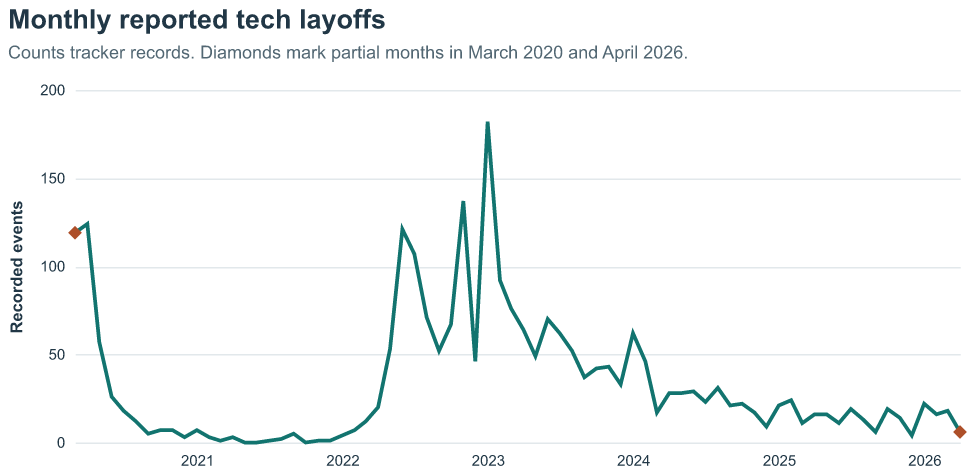

In [11]:
# One zero-weight row per month preserves empty months after filtering.
event_months = layoffs.assign(month_date=layoffs["date"].dt.to_period("M").dt.to_timestamp())
calendar = pd.DataFrame({"month_date": axis_months.to_timestamp(), "weight": 0})
monthly_input = pd.concat([event_months[["month_date", "industry", "country"]].assign(weight=1),
                           calendar], ignore_index=True)
monthly_input["boundary"] = monthly_input["month_date"].isin(
    [axis_months[0].start_time, axis_months[-1].start_time])

industry = alt.param(name="industry", value="All industries",
                     bind=alt.binding_select(options=["All industries", *sorted(layoffs.industry.unique())],
                                             name="Industry "))
hq = alt.param(name="hq", value="All countries",
               bind=alt.binding_select(options=["All countries", *sorted(layoffs.country.unique())],
                                       name="Headquarters "))
monthly = (alt.Chart(monthly_input).transform_filter(
    (alt.datum.weight == 0) |
    (((industry == "All industries") | (alt.datum.industry == industry)) &
     ((hq == "All countries") | (alt.datum.country == hq))))
    .transform_aggregate(events="sum(weight)", groupby=["month_date", "boundary"]))
tips = [alt.Tooltip("month_date:T", title="Month", format="%B %Y"),
        alt.Tooltip("events:Q", title="Recorded events", format=",d"),
        alt.Tooltip("boundary:N", title="Partial month")]
position = monthly.encode(
    x=alt.X("month_date:T", title=None, axis=alt.Axis(format="%Y", tickCount="year", grid=False)),
    y=alt.Y("events:Q", title="Recorded events", scale=alt.Scale(zero=True)),
    tooltip=tips)
line = position.mark_line(color=teal, strokeWidth=2.5)
points = position.mark_point(filled=True, size=85, opacity=0).encode(
    opacity=alt.condition(alt.datum.boundary, alt.value(1), alt.value(0.002)),
    color=alt.value(rust), shape=alt.value("diamond"))
empty = (monthly.transform_aggregate(total="sum(events)").transform_filter(alt.datum.total == 0)
         .mark_text(color=ink, size=14, align="left")
         .encode(x=alt.value(14), y=alt.value(30), text=alt.value("No recorded events for this selection.")))
timeline = (alt.layer(line, points, empty).add_params(industry, hq).properties(
    width=590, height=235, title=alt.Title("Monthly reported tech layoffs",
    subtitle="Counts tracker records. Diamonds mark partial months in March 2020 and April 2026.")))
show_altair(timeline, "Explore the timeline by industry and headquarters", 390)

The tracker recorded 697 events in 2022 and 802 in 2023, followed by 333 in 2024 and 174 in 2025. The highest full-year count was in 2023. Coverage begins March 13, 2020 and ends April 16, 2026. Annual counts for those two years cover shorter periods.

## 10. Which industries reported the most layoffs?

Rank industries by the number of records. Show headcount coverage alongside disclosed cuts so readers can tell how much of each total was observed.

In [12]:
sectors = (layoffs.groupby("industry")
           .agg(events=("company", "size"), disclosed_headcounts=("layoff_count", "count"),
                disclosed_cuts=("layoff_count", lambda s: s.sum(min_count=1)))
           .sort_values("events", ascending=False))
sectors["share_of_events_pct"] = 100 * sectors["events"] / len(layoffs)
assert sectors["events"].sum() == month_counts.sum()
display(sectors.round(1))

,events,disclosed_headcounts,disclosed_cuts,share_of_events_pct
industry,,,,
Finance,288,196,33927.0,11.7
Retail,216,144,79301.0,8.7
Healthcare,184,110,27312.0,7.4
Other,165,104,86943.0,6.7
Consumer,163,104,49811.0,6.6
Food,162,98,37765.0,6.6
Transportation,157,104,42157.0,6.4
Marketing,119,79,8792.0,4.8
Real Estate,99,63,9286.0,4.0


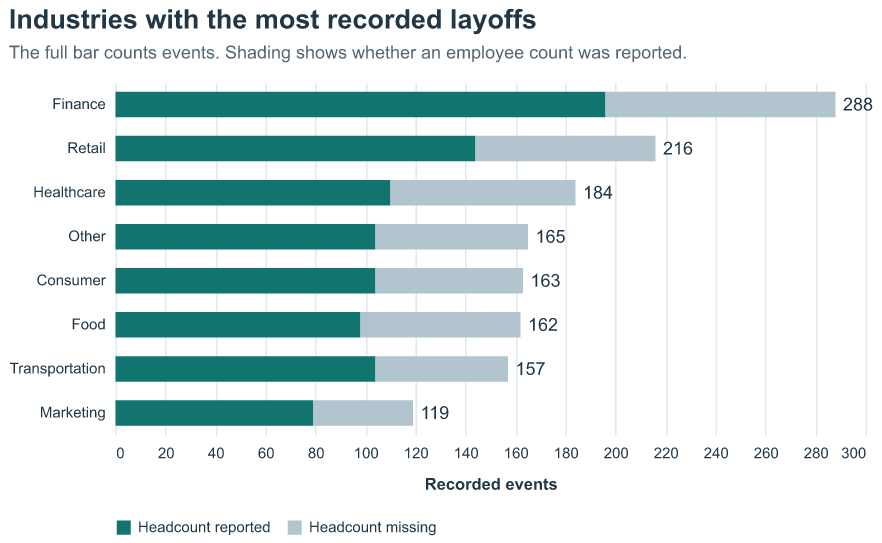

In [13]:
# An all-period entry and one entry per observed year allow the ranking to update on selection.
year_rows = layoffs.assign(period=layoffs["year"].astype(str))
period_rows = pd.concat([year_rows, year_rows.assign(period="Full period")], ignore_index=True)
ranked = (period_rows.groupby(["period", "industry"], as_index=False)
          .agg(events=("company", "size"), disclosed=("layoff_count", "count")))
ranked["missing"] = ranked["events"] - ranked["disclosed"]
ranked = ranked.sort_values(["period", "events", "industry"], ascending=[True, False, True])
ranked["rank"] = ranked.groupby("period").cumcount() + 1
assert ranked.loc[ranked.period.eq("Full period"), "events"].sum() == len(layoffs)
rank_long = ranked.melt(id_vars=["period", "industry", "rank", "events"],
                        value_vars=["disclosed", "missing"], var_name="status", value_name="records")
rank_long["status"] = rank_long["status"].map({"disclosed": "Headcount reported", "missing": "Headcount missing"})
rank_long["stack_order"] = rank_long["status"].eq("Headcount missing").astype(int)
year_pick = alt.param(name="year_pick", value="Full period",
                      bind=alt.binding_select(name="Period ", options=["Full period", *sorted(year_rows.period.unique())]))
ranking = (alt.Chart(rank_long).transform_filter(alt.datum.period == year_pick)
           .transform_filter(alt.datum["rank"] <= 8).add_params(year_pick))
row = alt.Y("industry:N", sort=alt.EncodingSortField(field="rank", op="min", order="ascending"), title=None)
bars = ranking.mark_bar(size=17).encode(
    y=row, x=alt.X("records:Q", title="Recorded events", stack="zero"),
    color=alt.Color("status:N", scale=alt.Scale(domain=["Headcount reported", "Headcount missing"],
                                               range=[teal, pale])),
    order="stack_order:Q", tooltip=[alt.Tooltip("industry:N", title="Industry"),
        alt.Tooltip("status:N", title="Disclosure"), alt.Tooltip("records:Q", title="Events in segment"),
        alt.Tooltip("events:Q", title="Total events")])
totals = (ranking.transform_filter(alt.datum.stack_order == 0)
          .mark_text(align="left", dx=5, color=ink, fontSize=12)
          .encode(y=row, x="events:Q", text="events:Q"))
industry_plot = (bars + totals).properties(width=500, height=235,
    title=alt.Title("Industries with the most recorded layoffs",
                    subtitle="The full bar counts events. Shading shows whether an employee count was reported."))
show_altair(industry_plot, "Compare the eight leading industries by year", 415)

Finance accounted for 288 of 2,470 records (11.7%). Retail followed with 216 (8.7%), a difference of 72 events. Industry employment and the number of firms at risk are unavailable, so these counts describe the tracker’s composition.

## 11. What did employers say about the March 2026 cuts?

March is the last full calendar month in the file. The evidence sheet lists all 18 tracker records and provides 17 public source links. Zendesk’s tracker entry cites an internal memo. Its reason remains unclear. The supporting text is paraphrased. The first applicable category is used in this order:

1. **AI took over work.** Management linked the reduction to AI doing work or enabling fewer people to do it.
2. **Other AI connection.** Management linked AI strategy or an AI-related change in the business to the cuts.
3. **Other stated reason.** Management identified another reason for the cuts or closure.
4. **Reason unclear.** An attributable explanation was unavailable or too vague to classify.

The table counts each distinct March company record once and flags cumulative updates. Unclear cases stay in the denominator. The project group reviewed all 18 classifications against the available evidence. AI assisted with drafting the evidence notes.

In [14]:
evidence = pd.read_csv("march_2026_evidence.csv", parse_dates=["event_date"], keep_default_na=False)
march = layoffs.loc[layoffs["month"].eq("2026-03"),
                    ["date", "company", "industry", "country", "source_url"]].rename(columns={"date": "event_date"})
review = march.merge(evidence, on=["event_date", "company"], validate="one_to_one",
                     how="outer", indicator=True).sort_values(["event_date", "company"])
assert len(review) == 18 and review["_merge"].eq("both").all()
assert review["source_url"].eq(review["original_source"]).all()
categories = ["AI took over work", "Other AI connection", "Other stated reason", "Reason unclear"]
assert review["category"].isin(categories).all()
assert review["record_type"].isin(["Cumulative update", "Reported round or closure"]).all()
classified = review[review["category"].ne("Reason unclear")]
assert classified["verified_url"].str.startswith("https://").all()
assert classified[["speaker", "supporting_paraphrase"]].ne("").all().all()
rounds = review[review["record_type"].eq("Reported round or closure")]
tally = pd.DataFrame({
    "All March records": review["category"].value_counts(),
    "Excluding cumulative updates": rounds["category"].value_counts()
}).reindex(categories).fillna(0).astype(int)
assert tally.sum().tolist() == [len(review), len(rounds)]
display(tally)

,All March records,Excluding cumulative updates
category,,
AI took over work,2,1
Other AI connection,3,3
Other stated reason,10,10
Reason unclear,3,3


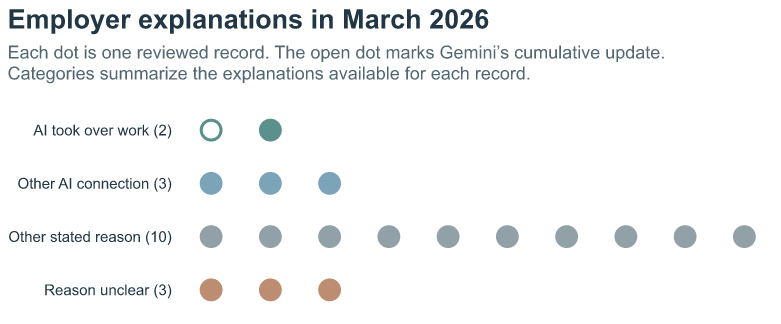

In [15]:
# Each dot represents one record in the source review.
evidence_dots = review.sort_values(["event_date", "company"]).copy()
evidence_dots["position"] = evidence_dots.groupby("category").cumcount() + 1
category_colors = ["#16605a", "#437d9b", "#637782", "#a05c36"]
category_labels = {c: f"{c}  ({tally.loc[c, 'All March records']})" for c in categories}
evidence_dots["label"] = evidence_dots["category"].map(category_labels)
dot_chart = (alt.Chart(evidence_dots).mark_point(size=175, strokeWidth=2).encode(
    x=alt.X("position:Q", axis=None, scale=alt.Scale(domain=[0.5, evidence_dots.position.max() + 0.5])),
    y=alt.Y("label:N", sort=list(category_labels.values()), title=None, axis=alt.Axis(grid=False)),
    color=alt.Color("category:N", scale=alt.Scale(domain=categories, range=category_colors), legend=None),
    fillOpacity=alt.condition(alt.datum.record_type == "Cumulative update", alt.value(0), alt.value(1)),
    fill=alt.Fill("category:N", scale=alt.Scale(domain=categories, range=category_colors), legend=None)
).properties(width=395, height=142, title=alt.Title("Employer explanations in March 2026",
    subtitle=["Each dot is one reviewed record. The open dot marks Gemini’s cumulative update.",
              "Categories summarize the explanations available for each record."])))
display(Image(data=vlc.vegalite_to_png(styled(dot_chart).to_dict(), scale=1.5), width=710))

In [16]:
# D3 selection 3.0.0, the selection module of D3 v7. Bundled for offline viewing.
# Source: https://cdn.jsdelivr.net/npm/d3-selection@3.0.0/dist/d3-selection.min.js
# Copyright 2010-2021 Mike Bostock
# 
# Permission to use, copy, modify, and/or distribute this software for any purpose
# with or without fee is hereby granted, provided that the above copyright notice
# and this permission notice appear in all copies.
# 
# THE SOFTWARE IS PROVIDED "AS IS" AND THE AUTHOR DISCLAIMS ALL WARRANTIES WITH
# REGARD TO THIS SOFTWARE INCLUDING ALL IMPLIED WARRANTIES OF MERCHANTABILITY AND
# FITNESS. IN NO EVENT SHALL THE AUTHOR BE LIABLE FOR ANY SPECIAL, DIRECT,
# INDIRECT, OR CONSEQUENTIAL DAMAGES OR ANY DAMAGES WHATSOEVER RESULTING FROM LOSS
# OF USE, DATA OR PROFITS, WHETHER IN AN ACTION OF CONTRACT, NEGLIGENCE OR OTHER
# TORTIOUS ACTION, ARISING OUT OF OR IN CONNECTION WITH THE USE OR PERFORMANCE OF
# THIS SOFTWARE.
import base64
import gzip

d3_selection_js = gzip.decompress(base64.b64decode(
    "H4sIAAAAAAAC/61bbXPbuLX+3l9hazoasoZpOel07lJmdBOv96WNnXSdTZPqqh6agiQmFKEFQdtaW//9PgfgCyiRtne7MxlLIoGD"
    "g4Pz+hzk6GhvodQq84+Opi+/ZJ6Qc3w5zHjCIxWL9Gjv5qU38AZ7p2K1lvF8ofZeDI4Hhy8GL473zuOvfO+NyJSIvv5pf5aneoqj"
    "WOre98T1F5DoBYFar7iY7fG7lZAq6/d7eTrlszjl095++XIppnnCR6lTjHL9XkmupmBm9fvm0wuX05H56ox7xbzeBGv7qeOooG2Z"
    "eSKuw+TDIs5G9VdfPTxgvzPXm74MFP48PNxv3I2j8I459a6wpzzje5mSMfY1vAnlXhr0SHoQ3u3trXf7Uovv+Jtvvjm6W6hl0mM8"
    "uM9u5n7LqBeDweAI73pMD/VTdpfE6Ve/kyC9xWAMbRny6fwtDfufozRc8mwVRlwPTbPOpfXbo95mWG5wT9IWza7UQdDrMRmkXgwh"
    "3r2bOT2/5w4lV7nEwFfBAMeoKUC2gYMJXpbEEXcGTLpuvw/xl0/kwbHrMu4twuzdbfpeihWXau2k7uhe8+nzcTphiYjCxFcb/Kv4"
    "iYmfYsnqFAyHPKDD8cRtyuW3IsqXPFVgVz+sJPDzTz9WHAdBkPb73JsWg88STh+NwTRmxL1I8lDxYgBY8LceXVw6kil3UzMq2hkt"
    "nuxyukMPsiIemPK0HGzaeX0odD7FhpzUjBwJP3Yhy3p8hoXrX5HFWZonCUxplPkdPP6Sc7m+1IYvaC2Li6SFznjiv5YyXHtxpj8x"
    "ZKSKRzMplkShIhBWa40n9dNZC9nwWey9TpImh4unz2AZqmjBs+a8Vdu8tOaqMYvO4SowW1xJoQS5FQ8+Zlpb0XRr1Vkss1LdThdx"
    "MtVU1i1UEsVlTWdZ07FlSiQjIiO5few3tiT57V5xIl7C07laWAPnxjvvKiUMtmlOO8YUNM3FDLhK+Z0K6PCK36tQamrFz6tpqMKr"
    "qyCtWbh9/Kisw3lNzDLOJIuZcO9nUEsSXs6yYMAieCezPZYEovg6zE6S4cFB5jp5kI6ziTty8poJgSdM4k+Qw6zpk2RFIqE37pAW"
    "AIWoQQHeLDZTasbubMZYbiw0YxFLWKhpnocrNqsZXFQMslVQn8/MLIndYNWZWTWqVl3RqkmQezD0xIlYVG2EZTjDA3jokNyqk7gj"
    "zWHkh17GlZOwyLUpLzTlipLZLWgITQMrht6cprmQlpaOvZYRWuhNYXmK06AuybVvw9CmvbhwsFEpzciS5rWlEKpauH5/Wb/fySoU"
    "ApGRbC/G7G4PdGYUv1zmJB0dHvvqVTqiv3D8A/8ivKiHX7QrqVZqyZfihr9WSASuc8ik4VBOnz/xcc//tsHwNimcs8UABloz3z97"
    "5i4HTUofuiiZIJx64WqVrE2mFMq5dhyZOzS+nI86pOW37YDb677549dtEbb/HHk0+DpvaGrDX/b7Ww9gMbMwT9THmN8+PKgq9cBA"
    "/bN+W9P/5RHlydQ64cWuqjSqoXrfGq/0BAXst56ux1sk3nWTINHLJ0QvR4+x6ndyIZtcfGzaajFlXk/5GCY5R5h+eKAToTenYrnC"
    "AU4vaShNBz9u25R6lS/twjaOTgfvsZpYXP30mFlhKGJcPfiH/06Dm0z45QrcWuHHhi5CgZExQHeTWDlH/3n4v+zgyNrrz43BURJm"
    "2ds4gyKSG//UcJT0676I7WLKq0iuY3+AVUmqteX2NLEejqLXs6h8b/ZfhmweEAdI0Q+PWVzFRYQKeRIPXdRy06mTjuXEovD5t1Ew"
    "2rZN5Gv7GX9vBN+wnl/bh35uGfpd1+E6Hec6+t7/7LYQ+ntpmgpZ1KlIFaVOvV494B+POAR7jp01/bO7bqJCrV3xdigaTUxHvZ5v"
    "6/W/ytXjFL7uhw/nbxv8/vsRfusZNrd//t3c1vQ6eFWqXJqS1Mv4GiX0HO6Xnpg09QIKTkvwdKpzc72QpT5pRWEl+U0s8qyTSpxm"
    "cDNvOPSVFye9NUJXAnoZawWunEYJVL+RqhCDCrYoDXWwMQrfyna8NTVKRMppprN/7LJ0h165/ijd2gbblp5rF+iie5nBH7hMrp72"
    "dCjTVk4DqyngGYJgVI1ieDWKwTWKYWEXHEgFUxaUwQFc3FOe6cPc4f1IuVy71laP6q6pf0Q6jGeO7cjgwwZwYfBjovZj8kSQL3MR"
    "GuDBkH3QuoRY0CcwFvPg4YHrGkw/oC+jdHxwECMw+FbOc3YDiZN75zAQx5AAApMUT/BVrIhVGBImj0oegti3wo5mfWNZU6SeyA2w"
    "p2oitmYfRkuBrYpihCwlbRaL8JAYQWKL3armg8yyIC7FlZ9k4D13McaRQTzOJ67eZlBKqt+XWkBBKSnXLsrb5CSNnGQtJ1nJyfCH"
    "IPXElEDUkwLushsRTzHqhnKPIC381g4ZwzEKSU7xrdA480yrndkA01SAE5aL+YIVS/l8w+JR7K3ybOHIIs+iYwigSzaMUx2hSeYo"
    "ecKpSe80B4a71FwNW4BX0Nb1XuzQZN+hKdMtMIvmOj390QPeN3JiWF2szHNM867z6+uEZ/gWhWnEkxC/sDoSYRXGScCLL67fnLh/"
    "jH8wRGTMMTJzgDHmTWyjS6orIBdPaOPaJTfLm9lvmNceiUBtXoM4wX2E01AyJ4jKnzMrsvgt5mADJq0eUYMrLs7Weuc3YfZnkMKW"
    "WQM8e5KXHSSQbYNvv41EidaxT7asYAcNMlaaWTls5Z6Qk7ZfaSVXLqtT1GYpWSSkdtbqfRFx6vT2ei4OjBnj93eDRTsDw9QECvst"
    "BR+EiJQd/xd8QFeg8GnWLcttVsDIZqMbDwsVjCldmNSA4UpZ0N7VXIp8lVXJuzmVzIbhruzMA8aN+eNxZdVbQPlkwhZ2kTC1Ql+P"
    "OiLp3MJkRrv0tlUKBLsXQwenJFCuvFKW6lypLptbKWZaVw2h1i5t38KN0KQgfNyAV7YGGNkxXuN30gLtyGkB6YpPOEXPKkABBkSA"
    "SscxmhlBVk4MA4kn1uzEBS44GM40TDlzHRFk45mG+/KgCIlw6zXSN2OZbqj0yicEcwkabiF0deRkIagBqhw2D1Y21QDKZ6S0bcko"
    "Pna9vxo9FsprX+moTh9Jxb+2peeIejyBgPFHQE5CS1m4NvSbjsUE6K8l48Ew1KBtSKBtNg61PGXhKYxQc1YLjIUkVFbEy9zdlVZc"
    "Sehx523GOGXvonXgrqSu6tSnwvJ1Xei0Sl/51KRwmyxhyhNckdMtGVs+j7H172XMNC+eZ3OLP9TmjMVlwLaLaZGxuDGZ4WCY6Dwx"
    "ITvLxwnpRZuRJYDw+/3I6IN42nho2lYcRiK6X6l82XZp79+wa3dYoECjO/912bcs6VdptBHJsFOQtw1Biio5JqFUkhMuWYz9M2r+"
    "NFISWko6DpLLSibwUjF9LIJZ3bm4LK0pZCEh+5YA0fZlV8GqHDuFGSa234NrWusjaD5bBlHz2cIdcpCfsSlbsyVbQbbVFm/YnJ2h"
    "DrgAy2cnV2D5jAqAm2A6PpuYAuvsVXAB4VwEZyjmhvvOPFiPL+jYDw4uMAOCLzpWc0BfVG5vioaqkRlOO6eteFc4CaTzGXkNfhcj"
    "UrB8w/TDlv5kMdUcmx4EhNc6Q12d3rg7ekSUnySHMc+jRslFQyvrRF8P1Yw5bqFfcK/m6R2hBYXKt5o5CiwYgY5CEol/dTXEQSuI"
    "Hpgs11FoJrkad92nXjuKhBRJum6fQTXtWaxEOUWJ2qGnRLoo+/14JL0ll3OOubisMCWO/XjD9LOGg7E8SE19pOyVULfzpn8hALv8"
    "HqPmKNRVYBuV8ZyHauEtkahR07FhPTFZz2AYneTQvahyQ9T04+OIbEbSxwINtcpmMjxp6DfMZDC80k25K9dJgnB8NXl4mOGvafpd"
    "oelXtCIjQJu0kKZBK2x5pqwjrGPzHV30DdMytd+Wu1BNSaUEUBB2UgGtKbxvtWdd7dPNjdrvYHwOpyEmw8NDgVR16OrSXJjspt//"
    "63+kFwGmB7Nlj+S9yGLNBvnfvBNOk/DPoC0rz2y2kuHGT1MlKtzOsYEKuvkxQpSu/RWvMyZ/Pz3c5xvYGFzqWe1sdhSnUpbYOk7p"
    "FmmK1GlKo0XNt/KURAvDmhy5XblLgk/K4hKP9khdi+bBx1sHX1oKiorQTulKeK6KTONBpUP2M+MRyvxNd/Pr/I0ZaVOF03Z3ZCu6"
    "uWbkszRsYCtYqoN7WmuY0S/Efcs8kQIInQLcG1CIYj0BRXkZa/ONDaayLP61wQrgLbAx0Kes64Y9ZNMzrU/uwYGq9Au+eblS693t"
    "7huokkBOcuBhtOhySs20ZqBdT7EJrtWFV1uNCQkc8wkzKJfYRrngQQVBXFX2EiN5rZQ5Z2LLMEIUoVv5iVFpfYUI4trOVE5emBFF"
    "6mG2VwGlxV2juNH4QauUF61SXvZTmyOQtW3stJSE5TglVl9SPfUv2u761QPe+B/88vt7/63rABXTyTB1+nbi3bZyFxt8dTxq4eGX"
    "9pXf+d+6ml4Zp9BXABbsf3Qs6VBezFZFc7EdlHkeE1/amfjB/0kz4RZwnlmVOpJMAwt82nrCP5o43HXItXH9bG/GLfFoXrt7sjRK"
    "r/bJaxukwuEwN7cwtf3jQkH2By3H3Lqn7/x09NX/tTpC6je1VSbbnFtiKyuav/vtNck//X+4lBfbQrP7Whumb1v+vkX/1bHon/1/"
    "7y5ataeAOIVxxrvutekVFGlTIm5b00uLERpm8q0W/KqjSMvre4ONqtXpWMnuh3XCnm4FS7aq4SOskCMsfYBq1/3Uj6gB8Bt4bqQL"
    "vJ1pJtufm0rAbGkbG2w5A0lnoFtdT8ECaiSUHytTMObL5ytd6VYs1IeppnZVt6SY6Ej66WpaQL0znZfndVQhm25zDsY7IN8dAT7L"
    "6D7tAG2pXLel6u1njqAGFa3TjDr6ClzQ5NE0v7Iq0EVUbiLpKVdF5RnqypMGSH2pj+rGallq71Dsk3V7JyraO3HZ3oka7Z3INFsg"
    "8qJb8Ahe/oinmik/VIX/3bDx5Xp5LRIvRgEVAmacVET/8vvTmzqBHlDeXI4TeuvCzp3XMU+me9ItsN+1TmCqe6JbMO6N1Tm9qdrX"
    "V0Hvf3sHzsHBGtdllLjUiK3z8m/2zVAN6VKClJrqQxdWIpeRae4MXVwKqBOk+jqnqhAQlNVERLe99gbmzrVusEa5pET1A7SO431a"
    "X4PRV6YuP35fQL+wRdKY8so1XrxHVavKOnb7eZ2kSO+O1kliEPkES19Xvz6zsa5bcZFXxncfZJhm2N4Srg28XIIeT08/nGuHfcNl"
    "RtHQ9e6IxGRDnVsa9kbgPxNAYqea4k8w7jJf6nhdMTaumDqkI56pw7R48BY/WMUk3iqxql5+EKtJiU2AxCqc80/MfH6ebG5s/HvZ"
    "CYbfKAbmHs1PAZHgugDO0zWxXl/cr8uwMtZXxw6FpSJTdVjV2FClq1BtbZZGc0MvS/+Zw7Scy6nICgr17PLCV2gklW3Hti4zehMU"
    "Z0ym3NVj0OmHISJkkJfX/SBNfDV3vmWwYNaV50Dav1De0XmQEmLgrap/ZEG7bDyltV9Dd88zEzoLJXK6fv7wgMzPZXatxUDnVWF8"
    "Zjcm7ARTVX0HBtwioUcaNu39GtO/e17Hxoyklg2zsBi0bKqfkHdk/dA8suKSX/AR327R8RK3wTl7py/7eua/8VjXBREWeXau/8tQ"
    "j92bvjiyUArhwz/9PwkN45LSNAAA"
)).decode("utf-8")

In [17]:
import json

# Serialize only the fields shown in the source cards.
card_columns = ["company", "event_date", "category", "record_type", "speaker",
                "supporting_paraphrase", "notes", "verified_url"]
cards = review[card_columns].copy()
cards["event_date"] = cards["event_date"].dt.strftime("%b %d, %Y")
card_json = cards.to_json(orient="records", force_ascii=True).replace("<", r"\u003c")
evidence_html = r'''
<!doctype html>
<html lang="en"><head><meta charset="utf-8"><title>March employer explanations</title>
<style>
*{box-sizing:border-box}body{margin:10px 8px;background:white;color:#213746;font:14px/1.45 system-ui,sans-serif}
main{max-width:760px}h3{margin:0 0 4px;font-size:20px}p{margin:3px 0 12px}
label{display:block;margin:12px 0 8px}select{font:inherit;padding:3px 6px;max-width:100%}
#summary{font-weight:600}#bars{display:grid;gap:4px;margin-bottom:15px}
.row{display:grid;grid-template-columns:minmax(108px,150px) 1fr 2em;align-items:center;gap:8px;
width:100%;min-height:34px;background:white;border:1px solid transparent;border-radius:4px;text-align:left;color:inherit;
font:inherit;cursor:pointer;padding:4px 8px}.row:hover,.row[aria-pressed=true]{background:#edf4f3}
.row:focus-visible,select:focus-visible,a:focus-visible{outline:2px solid #94501e;outline-offset:1px}
.track{background:#f1f4f5;height:13px}.fill{display:block;height:100%}.value{text-align:right;font-variant-numeric:tabular-nums}
h4{font-size:16px;margin:10px 0 4px}.case{border-top:1px solid #dce3e6;padding:8px 0}
.case p{margin:3px 0}.meta{color:#506371;font-size:13px}.case a{color:#135d67}
</style></head><body><main>
<h3>What employers said about the cuts</h3>
<p>March 2026 · Select a category to read the supporting evidence.</p>
<label>Include <select id="scope"><option value="all">All March records</option>
<option value="rounds">Reported rounds and closures only</option></select></label>
<p id="summary" aria-live="polite"></p><div id="bars" aria-label="Explanation categories"></div>
<h4 id="heading" aria-live="polite"></h4><section id="cases" aria-labelledby="heading"></section>
</main><script>__D3_LIBRARY__</script><script>
const records = __EVIDENCE__;
const categories = __CATEGORIES__;
const colors = __COLORS__;
let selected = categories[0];
const scope = d3.select("#scope");

function render() {
  const visible = records.filter(d => scope.property("value") === "all" || d.record_type !== "Cumulative update");
  const counts = categories.map((name, i) => ({
    name, color: colors[i], cases: visible.filter(d => d.category === name)
  }));
  d3.select("#summary").text(visible.length + " reviewed records");
  const rows = d3.select("#bars").selectAll("button").data(counts, d => d.name)
    .join(enter => {
      const button = enter.append("button").attr("type","button").attr("class","row");
      button.append("span").attr("class","label");
      button.append("span").attr("class","track").append("span").attr("class","fill");
      button.append("b").attr("class","value");
      return button;
    })
    .attr("aria-pressed", d => String(d.name === selected))
    .attr("aria-label", d => d.name + ", " + d.cases.length + " records")
    .on("click", (_, d) => { selected = d.name; render(); });
  rows.select(".label").text(d => d.name);
  rows.select(".fill").style("background", d => d.color)
    .style("width", d => 100 * d.cases.length / visible.length + "%");
  rows.select(".value").text(d => d.cases.length);

  const cases = counts.find(d => d.name === selected).cases;
  d3.select("#heading").text(selected + " · " + cases.length + (cases.length === 1 ? " record" : " records"));
  const cards = d3.select("#cases").selectAll("article").data(cases, d => d.company).join("article").attr("class","case").order();
  cards.each(function(d) {
    const card = d3.select(this);
    card.selectAll("*").remove();
    card.append("strong").text(d.company);
    card.append("div").attr("class","meta").text([d.event_date, d.speaker,
      d.record_type === "Cumulative update" ? "Cumulative update since January" : ""].filter(Boolean).join(" · "));
    if (d.supporting_paraphrase) card.append("p").text(d.supporting_paraphrase);
    if (d.notes) card.append("p").attr("class","meta").text(d.notes);
    if (d.verified_url.startsWith("https://")) card.append("a").attr("href",d.verified_url)
      .attr("target","_blank").attr("rel","noopener noreferrer").text("Read source for " + d.company);
  });
}
scope.on("change",render);
render();
</script></body></html>
'''
evidence_html = (evidence_html.replace("__D3_LIBRARY__", d3_selection_js)
                 .replace("__CATEGORIES__", json.dumps(categories))
                 .replace("__COLORS__", json.dumps(category_colors))
                 .replace("__EVIDENCE__", card_json))
inline_explorer(evidence_html, "Explore March explanations and read employer sources", 565)

In [18]:
from IPython.display import Markdown
columns = ["event_date", "company", "category", "speaker", "supporting_paraphrase", "notes", "verified_url"]
for date, company, category, speaker, passage, note, url in review[columns].itertuples(index=False, name=None):
    source = f" [Source]({url})" if url else ""
    attribution = f" ({speaker})" if speaker else ""
    display(Markdown(f"**{date:%b %d} · {company} — {category}**{attribution}. {passage} {note}{source}"))

**Mar 13 · Digg — Other AI connection** (Justin Mezzell, CEO). Mezzell described AI spam overwhelming the relaunched site as Digg scaled back and rebuilt. External bots harmed the product. No claim of employees being replaced. [Source](https://techcrunch.com/2026/03/13/digg-lays-off-staff-and-shuts-down-app-as-company-retools/)

**Mar 13 · Stone — Other stated reason** (Stone, company statement). Stone described simplifying its structure to improve efficiency. An unnamed source mentioned AI. Stone's own statement gave a different level of detail. [Source](https://jovempan.com.br/noticias/economia/stone-faz-demissao-em-massa-e-desliga-cerca-de-400-funcionarios.html)

**Mar 17 · FranShares — Other stated reason** (Kenny Rose, founder). Rose attributed the shutdown to insufficient capital and marketplace challenges.  [Source](https://www.bizjournals.com/chicago/news/2026/03/17/franshares-chicago-startup-shuts-down.html)

**Mar 19 · Crypto.com — Other AI connection** (Crypto.com spokesperson). The company linked the reduction to an enterprise-wide AI rollout, a shift in resources and efficiency goals. The statement identifies no task taken over by AI. [Source](https://www.straitstimes.com/singapore/singapore-based-crypto-com-lays-off-12-of-staff-third-cut-in-four-years)

**Mar 19 · Snowflake — Other stated reason** (Snowflake spokesperson). The spokesperson described targeted adjustments to align teams with the company's long-term strategy as it grew. Earlier comments about AI products did not identify the reason for this round. [Source](https://www.businessinsider.com/snowflake-layoffs-strategy-ai-growth-2026-3)

**Mar 20 · Gemini — AI took over work** (Cameron and Tyler Winklevoss, shareholder letter). The founders linked AI-assisted production code changes to operating with a smaller team and described a roughly 30% workforce reduction since January. March disclosure of a cumulative reduction. A distinct new March round cannot be established. [Source](https://investors.gemini.com/static-files/9930b4f9-4e24-4f9a-8b7b-fb5066554c86)

... (8 outputs left out)

**Mar 31 · Monzo — Other stated reason** (Monzo, company statement). Monzo said it would close its U.S. operation and concentrate on the UK and Europe. The company headquarters and the affected operation are in different countries. [Source](https://www.bloomberg.com/news/articles/2026-03-31/fintech-monzo-shutting-down-us-operations-to-focus-on-uk-europe)

**Mar 31 · Oracle — Reason unclear** (Oracle, employee notification). The notice described a broader organizational change without identifying what drove it. Coverage discussed AI spending. The March notice did not attribute the round to AI or explain the underlying change. [Source](https://www.sfgate.com/tech/article/oracle-layoffs-ai-22175253.php/)

**Mar 31 · Rec Room — Other stated reason** (Rec Room, closure announcement). Rec Room said costs exceeded revenue and changes in the VR and gaming markets made profitability unattainable. The company announced the wind-down March 30. The tracker records March 31. [Source](https://techcrunch.com/2026/03/31/social-gaming-platform-rec-room-once-valued-at-3-5b-is-shutting-down/)

**Mar 31 · Yupp — Other AI connection** (Yupp founders, including CEO Pankaj Gupta). The founders linked closure to weak demand for their evaluation product as model capabilities rapidly improved. The AI connection concerns the market for the product. [Source](https://techcrunch.com/2026/03/31/yupp-ai-shuts-down-33m-a16z-crypto-chris-dixon/)

**Two ways AI figured in employers’ accounts.** Monte Carlo’s CEO connected smaller teams to specific changes in the work, including support staff resolving issues that previously required escalation. Crypto.com described shifting resources as it introduced AI across the company. Its spokesperson did not name an affected task. [Monte Carlo CEO statement](https://www.linkedin.com/posts/barrmoses_last-week-monte-carlo-restructured-we-said-activity-7442630711016058880-1k11) · [Crypto.com spokesperson](https://www.straitstimes.com/singapore/singapore-based-crypto-com-lays-off-12-of-staff-third-cut-in-four-years)

**Why the denominator matters.** Gemini’s shareholder letter links AI-assisted coding to a smaller workforce, but the 30% reduction spans the year to date. The 18-record column includes what Gemini reported in March. The 17-record column excludes that cumulative update when describing dated rounds or closures. Zendesk remains in both denominators because the tracker cites an internal memo whose explanation could not be verified. [Gemini shareholder letter](https://investors.gemini.com/static-files/9930b4f9-4e24-4f9a-8b7b-fb5066554c86)

## 12. Supporting comparison by employer AI-focus flag

The source dataset describes the flag as identifying AI-, machine-learning- or data-focused employers. The precise rule is undocumented. Some industries have only flagged records, and Clearbit appears under both labels. Here “Non-AI-focused” means the source flag is false. These comparisons describe reported events with a disclosed outcome.

In [19]:
overall = layoffs.groupby("ai_group").agg(
    events=("company", "size"), known_counts=("layoff_count", "count"),
    median_count=("layoff_count", "median"), known_pcts=("pct_workforce", "count"),
    median_pct=("pct_workforce", "median"))
overall["pct_with_workforce_pct"] = (100 * overall["known_pcts"] / overall["events"]).round(1)
display(overall)

,events,known_counts,median_count,known_pcts,median_pct,pct_with_workforce_pct
ai_group,,,,,,
AI-focused,355,217,77.0,202,18.0,56.9
Non-AI-focused,2115,1375,90.0,1332,19.0,63.0


Of the 355 flagged events, 202 disclosed a workforce percentage and the median was 18%. Of the 2,115 unflagged events, 1,332 disclosed a percentage and the median was 19%. For employee counts, the medians were 77 and 90 among 217 and 1,375 reporting events, respectively. Incomplete disclosure can affect all four estimates.

### Sensitivity to industry mix

Restrict the comparison to industries containing at least one record of each label. This removes industries with observations on only one side. Medians in the restricted table are still pooled across industries and can reflect differences in the industry mix.

In [20]:
industry_groups = pd.crosstab(layoffs["industry"], layoffs["ai_group"])
overlap = industry_groups.index[industry_groups.gt(0).all(axis=1)]
mixed = layoffs[layoffs["industry"].isin(overlap)]
display(mixed.groupby("ai_group").agg(events=("company", "size"), known_counts=("layoff_count", "count"),
                                      median_count=("layoff_count", "median"), known_pcts=("pct_workforce", "count"),
                                      median_pct=("pct_workforce", "median")))

,events,known_counts,median_count,known_pcts,median_pct
ai_group,,,,,
AI-focused,110,64,100.0,44,20.0
Non-AI-focused,1943,1260,90.0,1227,19.0


### Funding stage and headquarters geography

Funding stage describes financing and maturity. Workforce size before a layoff is unavailable. Country identifies headquarters, which may differ from the location of affected jobs. The tables report how many records disclosed each measure used for a median.

In [21]:
def stage_group(stage):
    if stage in ["Seed", "Series A", "Series B"]:
        return "Early stage"
    if stage.startswith("Series"):
        return "Late stage"
    if stage == "Post-IPO":
        return "Public"
    return "Other / Unknown"

layoffs["stage_group"] = layoffs["stage"].apply(stage_group)
STAGE_ORDER = ["Early stage", "Late stage", "Public", "Other / Unknown"]

stage_summary = (layoffs.groupby(["stage_group", "ai_group"])
                 .agg(layoff_events=("company", "size"),
                      known_counts=("layoff_count", "count"),
                      known_pcts=("pct_workforce", "count"),
                      median_layoff_count=("layoff_count", "median"),
                      median_pct_workforce=("pct_workforce", "median"),
                      known_funding=("raised_mm", "count"),
                      median_raised_mm=("raised_mm", "median"))
                 .reindex(STAGE_ORDER, level=0))

# Share of each group's events that fall in each stage
stage_summary["pct_of_group_events"] = (
    stage_summary["layoff_events"] /
    stage_summary.groupby(level="ai_group")["layoff_events"].transform("sum") * 100
)
stage_summary.round(1)

layoff_events  known_counts  known_pcts  \
stage_group     ai_group                                                  
Early stage     AI-focused                 86            48          59   
                Non-AI-focused            458           271         319   
Late stage      AI-focused                 88            55          60   
                Non-AI-focused            586           408         383   
Public          AI-focused                 88            60          37   
                Non-AI-focused            473           334         306   
Other / Unknown AI-focused                 93            54          46   
                Non-AI-focused            598           362         324   

                                median_layoff_count  median_pct_workforce  \
stage_group     ai_group                                                    
Early stage     AI-focused                     30.0                  25.0   
                Non-AI-focused                 40.0                  31.0   
Late stage      AI-focused                     75.0                  15.0   
                Non-AI-focused                 90.0                  15.0   
Public          AI-focused                    205.0                   7.0   
                Non-AI-focused                200.0                  10.0   
Other / Unknown AI-focused                     72.0                  20.0   
                Non-AI-focused                 88.5                  20.0   

                                known_funding  median_raised_mm  \
stage_group     ai_group                                          
Early stage     AI-focused                 85              49.0   
                Non-AI-focused            434              36.0   
Late stage      AI-focused                 88             326.5   
                Non-AI-focused            575             281.0   
Public          AI-focused                 73             188.0   
                Non-AI-focused            422             450.0   
Other / Unknown AI-focused                 66             135.5   
                Non-AI-focused            436             138.0   

                                pct_of_group_events  
stage_group     ai_group                             
Early stage     AI-focused                     24.2  
                Non-AI-focused                 21.7  
Late stage      AI-focused                     24.8  
                Non-AI-focused                 27.7  
Public          AI-focused                     24.8  
                Non-AI-focused                 22.4  
Other / Unknown AI-focused                     26.2  
                Non-AI-focused                 28.3

In [22]:
region = layoffs["country"].map(lambda c: c if c in ("United States", "Unknown") else "Outside U.S.")
geography = layoffs.assign(hq_region=region).groupby(["hq_region", "ai_group"]).agg(
    events=("company", "size"), known_counts=("layoff_count", "count"), median_count=("layoff_count", "median"),
    known_pcts=("pct_workforce", "count"), median_pct=("pct_workforce", "median"))
display(geography)

events  known_counts  median_count  known_pcts  \
hq_region     ai_group                                                         
Outside U.S.  AI-focused         122            75          45.0          75   
              Non-AI-focused     819           561         100.0         514   
United States AI-focused         233           142         100.0         127   
              Non-AI-focused    1294           813          88.0         817   
Unknown       Non-AI-focused       2             1          55.0           1   

                              median_pct  
hq_region     ai_group                    
Outside U.S.  AI-focused            24.0  
              Non-AI-focused        20.0  
United States AI-focused            15.0  
              Non-AI-focused        17.0  
Unknown       Non-AI-focused       100.0

### Exploratory distribution checks

Rank tests compare employee counts and workforce percentages for the two groups. Repeating both comparisons in shared industries gives four exploratory tests. Holm adjustment accounts for testing four comparisons. The rank effect is positive when the flagged group tends to have larger values. Repeated employers and selective reporting limit inference from these event-level tests.

In [23]:
import numpy as np
from scipy.stats import mannwhitneyu

comparisons = []
for scope, frame in [("All records", layoffs), ("Shared industries", mixed)]:
    for metric in ["layoff_count", "pct_workforce"]:
        a = frame.loc[frame["is_ai_company"], metric].dropna().astype(float)
        b = frame.loc[~frame["is_ai_company"], metric].dropna().astype(float)
        test = mannwhitneyu(a, b, alternative="two-sided")
        comparisons.append(dict(scope=scope, metric=metric, n_flagged=len(a), n_unflagged=len(b),
                                rank_effect=2 * test.statistic / (len(a) * len(b)) - 1, p=test.pvalue))
tests = pd.DataFrame(comparisons).sort_values("p")
factors = np.arange(len(tests), 0, -1)
tests["holm_p"] = np.minimum(1, np.maximum.accumulate(tests["p"].to_numpy() * factors))
display(tests.sort_index().round(3))

,scope,metric,n_flagged,n_unflagged,rank_effect,p,holm_p
0,All records,layoff_count,217,1375,-0.075,0.074,0.245
1,All records,pct_workforce,202,1332,-0.050,0.248,0.496
2,Shared industries,layoff_count,64,1260,0.139,0.061,0.245
3,Shared industries,pct_workforce,44,1227,-0.074,0.401,0.496


## 13. Answer to the project question

Reported events peaked in 2023, and finance contributed the most records across the full period. The March source review identifies different mechanisms. Some employers described AI enabling a smaller team, some described AI changing strategy or demand, and others gave business reasons such as closure or weak revenue. Several announcements leave the underlying reason unclear.

The category totals above measure what employers publicly attributed to these reductions. They cannot establish how many jobs AI replaced, a layoff rate for all tech firms, or explanations for months outside March.